In [ ]:

%pip install -q kagglehub



In [1]:
!pip install -q ultralytics kagglehub pyyaml opencv-python matplotlib pandas

In [2]:
from pathlib import Path

for p in Path("/content").rglob("data.yaml"):
    print(p)

In [ ]:

import kagglehub

# Download the dataset
path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Path to dataset files: /kaggle/input/neu-surface-defect-database


In [ ]:

from pathlib import Path

DATASET_DIR = Path(path)

print("Dataset directory:", DATASET_DIR)
print("\nContents:")

for item in DATASET_DIR.iterdir():
    print(("DIR  " if item.is_dir() else "FILE "), item.name)


Dataset directory: /kaggle/input/neu-surface-defect-database

Contents:
DIR   NEU-DET


In [3]:

from collections import Counter

files = [p for p in DATASET_DIR.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("File extensions:", Counter(
    p.suffix.lower() or "(no extension)" for p in files
))

print("\nFirst 40 files:")
for p in files[:40]:
    print(p.relative_to(DATASET_DIR))


NameError: name 'DATASET_DIR' is not defined

In [5]:
from pathlib import Path

DATASET_DIR = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")

print("Dataset folder exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    print("Subfolders:", [p.name for p in DATASET_DIR.iterdir()])
else:
    print("Please check the dataset path.")

Dataset folder exists: False
Please check the dataset path.


In [6]:
from pathlib import Path

for base in [Path("/kaggle/input"), Path("/content")]:
    print(f"\nChecking: {base}")
    if base.exists():
        for p in base.iterdir():
            print(" ", p)
    else:
        print("  Folder does not exist")


Checking: /kaggle/input

Checking: /content
  /content/.config
  /content/best.pt
  /content/sample_data


In [7]:
!pip install -q kagglehub

import kagglehub
from pathlib import Path

path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

DATASET_DIR = Path(path)

print("Dataset downloaded to:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())
print("Contents:", list(DATASET_DIR.iterdir()))

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset downloaded to: /kaggle/input/neu-surface-defect-database
Dataset exists: True
Contents: [PosixPath('/kaggle/input/neu-surface-defect-database/NEU-DET')]


In [8]:
from pathlib import Path

DATASET_DIR = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")

print("Dataset folder:", DATASET_DIR)

for p in DATASET_DIR.iterdir():
    print(" -", p.name)

Dataset folder: /kaggle/input/neu-surface-defect-database/NEU-DET
 - validation
 - train


In [9]:
from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/neu-surface-defect-database/NEU-DET"
)

for split in ["train", "validation"]:
    folder = DATASET_DIR / split
    print(f"\n{split.upper()} folder exists:", folder.exists())

    if folder.exists():
        for p in folder.iterdir():
            print("  ", p.name)


TRAIN folder exists: True
   annotations
   images

VALIDATION folder exists: True
   annotations
   images


In [4]:
from pathlib import Path

DATASET_DIR = Path("/kaggle/input/neu-surface-defect-database")

print("Dataset exists:", DATASET_DIR.exists())
print("Dataset folders:", list(DATASET_DIR.iterdir()))

Dataset exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/neu-surface-defect-database'

In [ ]:

from pathlib import Path
from collections import Counter

DATASET_DIR = Path(path) / "NEU-DET"

print("Dataset root:", DATASET_DIR)

for folder in sorted(DATASET_DIR.rglob("*")):
    if folder.is_dir():
        files_here = sum(1 for f in folder.iterdir() if f.is_file())
        print(f"{folder.relative_to(DATASET_DIR)} : {files_here} direct files")


Dataset root: /kaggle/input/neu-surface-defect-database/NEU-DET
train : 0 direct files
train/annotations : 1439 direct files
train/images : 0 direct files
train/images/crazing : 240 direct files
train/images/inclusion : 240 direct files
train/images/patches : 240 direct files
train/images/pitted_surface : 240 direct files
train/images/rolled-in_scale : 240 direct files
train/images/scratches : 240 direct files
validation : 0 direct files
validation/annotations : 361 direct files
validation/images : 0 direct files
validation/images/crazing : 60 direct files
validation/images/inclusion : 60 direct files
validation/images/patches : 60 direct files
validation/images/pitted_surface : 60 direct files
validation/images/rolled-in_scale : 60 direct files
validation/images/scratches : 60 direct files


In [ ]:

import xml.etree.ElementTree as ET

xml_files = sorted(DATASET_DIR.rglob("*.xml"))
assert xml_files, "No XML annotations found."

xml_path = xml_files[0]
root = ET.parse(xml_path).getroot()

print("XML file:", xml_path.name)
print("Image filename:", root.findtext("filename"))
print("Image dimensions:")

size = root.find("size")
if size is not None:
    print("Width:", size.findtext("width"))
    print("Height:", size.findtext("height"))

print("\nObjects:")
for obj in root.findall("object"):
    name = obj.findtext("name")
    box = obj.find("bndbox")

    print("Class:", name)
    if box is not None:
        print({
            key: box.findtext(key)
            for key in ["xmin", "ymin", "xmax", "ymax"]
        })


XML file: crazing_1.xml
Image filename: crazing_1.jpg
Image dimensions:
Width: 200
Height: 200

Objects:
Class: crazing
{'xmin': '2', 'ymin': '2', 'xmax': '193', 'ymax': '194'}


In [ ]:

from collections import defaultdict

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
images_by_stem = defaultdict(list)

for img in DATASET_DIR.rglob("*"):
    if img.is_file() and img.suffix.lower() in image_extensions:
        images_by_stem[img.stem].append(img)

xml_stems = [p.stem for p in xml_files]

missing_images = [
    p.name for p in xml_files
    if p.stem not in images_by_stem
]

duplicate_image_stems = {
    stem: paths for stem, paths in images_by_stem.items()
    if len(paths) > 1
}

print("XML annotations:", len(xml_files))
print("Images:", sum(map(len, images_by_stem.values())))
print("Annotations without matching image:", len(missing_images))
print("Duplicate image stems:", len(duplicate_image_stems))

if missing_images:
    print("Examples:", missing_images[:10])

if duplicate_image_stems:
    print("Duplicate examples:", list(duplicate_image_stems)[:10])


XML annotations: 1800
Images: 1800
Annotations without matching image: 0
Duplicate image stems: 0


In [ ]:

from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches",
]

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]
xml_files = list(DATASET_DIR.rglob("*.xml"))

xml_by_stem = {}
for xml_path in xml_files:
    if xml_path.stem in xml_by_stem:
        raise ValueError(f"Duplicate XML stem: {xml_path.stem}")
    xml_by_stem[xml_path.stem] = xml_path

image_by_stem = {}
for img_path in image_files:
    if img_path.stem in image_by_stem:
        raise ValueError(f"Duplicate image stem: {img_path.stem}")
    image_by_stem[img_path.stem] = img_path

missing_xml = set(image_by_stem) - set(xml_by_stem)
missing_images = set(xml_by_stem) - set(image_by_stem)

print("Images:", len(image_by_stem))
print("XML files:", len(xml_by_stem))
print("Images without XML:", len(missing_xml))
print("XML without image:", len(missing_images))

assert not missing_xml, f"Missing annotations: {list(missing_xml)[:10]}"
assert not missing_images, f"Missing images: {list(missing_images)[:10]}"

class_counts = Counter()
for xml_path in xml_files:
    root = ET.parse(xml_path).getroot()
    for obj in root.findall("object"):
        name = obj.findtext("name")
        class_counts[name] += 1

print("\nAnnotated object counts:")
for name in CLASS_NAMES:
    print(f"{name}: {class_counts[name]}")

unexpected = set(class_counts) - set(CLASS_NAMES)
assert not unexpected, f"Unexpected class names: {unexpected}"

print("\nAudit passed.")


Images: 1800
XML files: 1800
Images without XML: 0
XML without image: 0

Annotated object counts:
crazing: 689
inclusion: 1011
patches: 881
pitted_surface: 432
rolled-in_scale: 628
scratches: 548

Audit passed.


In [ ]:

from pathlib import Path
from collections import Counter
import random
import shutil
import xml.etree.ElementTree as ET

# --------------------------------------------------
# 1. Paths and class mapping
# --------------------------------------------------
SOURCE = DATASET_DIR
OUTPUT = Path("/content/neu_yolo")

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches",
]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
SEED = 42
TEST_PER_CLASS = 30

# --------------------------------------------------
# 2. Collect all XML annotations by filename stem
# --------------------------------------------------
xml_by_stem = {}

for xml_path in SOURCE.rglob("*.xml"):
    if xml_path.stem in xml_by_stem:
        raise ValueError(f"Duplicate XML annotation: {xml_path.stem}")
    xml_by_stem[xml_path.stem] = xml_path

# --------------------------------------------------
# 3. Collect images from the original splits
# --------------------------------------------------
original_train = {}
original_val = {}

for class_name in CLASS_NAMES:
    train_folder = SOURCE / "train" / "images" / class_name
    val_folder = SOURCE / "validation" / "images" / class_name

    train_images = sorted(
        p for p in train_folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    val_images = sorted(
        p for p in val_folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    assert len(train_images) == 240, (
        f"{class_name}: expected 240 training images, got {len(train_images)}"
    )
    assert len(val_images) == 60, (
        f"{class_name}: expected 60 validation images, got {len(val_images)}"
    )

    original_train[class_name] = train_images
    original_val[class_name] = val_images

# --------------------------------------------------
# 4. Make a reproducible, class-balanced test split
# --------------------------------------------------
rng = random.Random(SEED)

splits = {"train": [], "val": [], "test": []}

for class_name in CLASS_NAMES:
    candidates = original_train[class_name].copy()
    rng.shuffle(candidates)

    test_images = candidates[:TEST_PER_CLASS]
    train_images = candidates[TEST_PER_CLASS:]

    splits["train"].extend(train_images)
    splits["test"].extend(test_images)
    splits["val"].extend(original_val[class_name])

# --------------------------------------------------
# 5. Convert Pascal VOC XML boxes to YOLO format
# --------------------------------------------------
def convert_xml_to_yolo(xml_path, image_path):
    root = ET.parse(xml_path).getroot()

    filename = root.findtext("filename")
    if filename and Path(filename).stem != image_path.stem:
        raise ValueError(
            f"Filename mismatch: {filename} vs {image_path.name}"
        )

    size = root.find("size")
    if size is None:
        raise ValueError(f"Missing image size in {xml_path.name}")

    width = int(size.findtext("width"))
    height = int(size.findtext("height"))

    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid dimensions in {xml_path.name}")

    lines = []

    for obj in root.findall("object"):
        class_name = obj.findtext("name")

        if class_name not in CLASS_TO_ID:
            raise ValueError(
                f"Unexpected class {class_name} in {xml_path.name}"
            )

        box = obj.find("bndbox")
        if box is None:
            raise ValueError(f"Missing bounding box in {xml_path.name}")

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        # Clamp coordinates to image boundaries
        xmin = max(0.0, min(xmin, width))
        xmax = max(0.0, min(xmax, width))
        ymin = max(0.0, min(ymin, height))
        ymax = max(0.0, min(ymax, height))

        if xmax <= xmin or ymax <= ymin:
            raise ValueError(f"Invalid box in {xml_path.name}")

        x_center = ((xmin + xmax) / 2) / width
        y_center = ((ymin + ymax) / 2) / height
        box_width = (xmax - xmin) / width
        box_height = (ymax - ymin) / height

        lines.append(
            f"{CLASS_TO_ID[class_name]} "
            f"{x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

    if not lines:
        raise ValueError(f"No objects found in {xml_path.name}")

    return "\n".join(lines) + "\n"

# --------------------------------------------------
# 6. Create output folders and convert every image
# --------------------------------------------------
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split_name, images in splits.items():
    image_out = OUTPUT / "images" / split_name
    label_out = OUTPUT / "labels" / split_name

    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    for image_path in images:
        xml_path = xml_by_stem.get(image_path.stem)

        if xml_path is None:
            raise FileNotFoundError(
                f"No XML annotation for {image_path.name}"
            )

        # Preserve the original filename so matching remains unambiguous
        shutil.copy2(image_path, image_out / image_path.name)

        yolo_text = convert_xml_to_yolo(xml_path, image_path)
        label_path = label_out / f"{image_path.stem}.txt"
        label_path.write_text(yolo_text)

# --------------------------------------------------
# 7. Create YOLO dataset configuration
# --------------------------------------------------
yaml_text = (
    f"path: {OUTPUT}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n"
)

for class_id, class_name in enumerate(CLASS_NAMES):
    yaml_text += f"  {class_id}: {class_name}\n"

(OUTPUT / "data.yaml").write_text(yaml_text)

# --------------------------------------------------
# 8. Verify counts and report
# --------------------------------------------------
print("YOLO conversion completed.")
print("Dataset location:", OUTPUT)
print("Configuration:", OUTPUT / "data.yaml")

expected = {"train": 1260, "val": 360, "test": 180}

for split_name, images in splits.items():
    image_count = len(list(
        (OUTPUT / "images" / split_name).glob("*")
    ))
    label_count = len(list(
        (OUTPUT / "labels" / split_name).glob("*.txt")
    ))

    assert image_count == expected[split_name], (
        f"{split_name}: unexpected image count {image_count}"
    )
    assert label_count == image_count, (
        f"{split_name}: image/label count mismatch"
    )

    print(
        f"{split_name}: {image_count} images, "
        f"{label_count} label files"
    )

    split_classes = Counter(p.parent.name for p in images)
    # Count images according to their original class folder
    class_counts = Counter(
        CLASS_NAMES.index(p.parent.name)
        for p in images
        if p.parent.name in CLASS_NAMES
    )

    print("  Expected class-balanced split verified by source folders.")

print("\nYOLO data.yaml:")
print((OUTPUT / "data.yaml").read_text())


YOLO conversion completed.
Dataset location: /content/neu_yolo
Configuration: /content/neu_yolo/data.yaml
train: 1260 images, 1260 label files
  Expected class-balanced split verified by source folders.
val: 360 images, 360 label files
  Expected class-balanced split verified by source folders.
test: 180 images, 180 label files
  Expected class-balanced split verified by source folders.

YOLO data.yaml:
path: /content/neu_yolo
train: images/train
val: images/val
test: images/test
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches



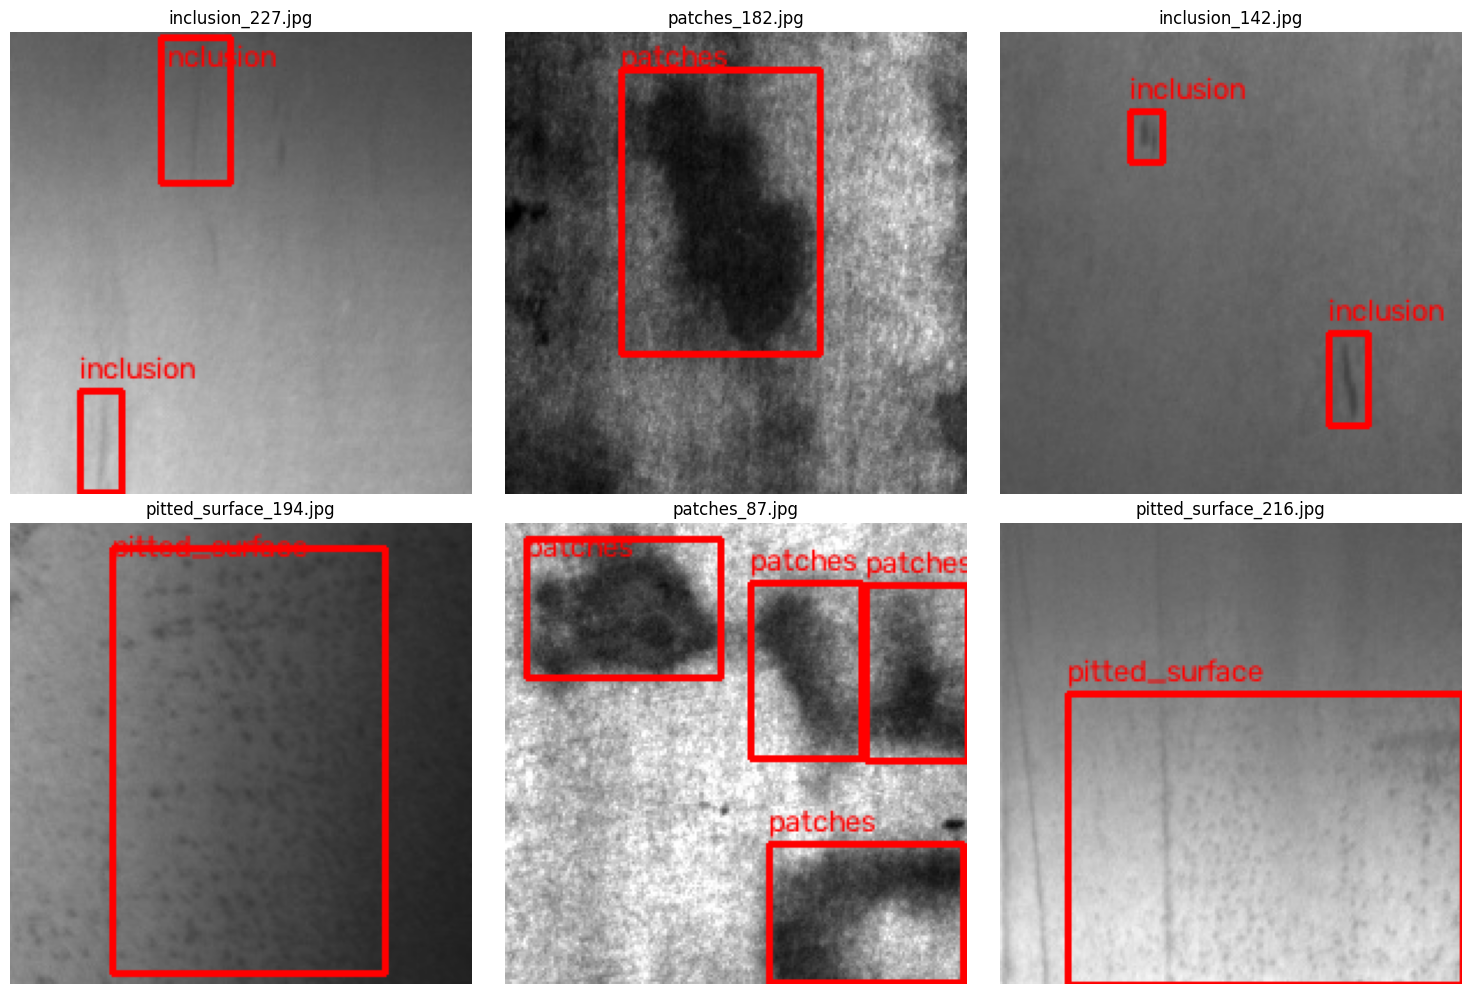

In [ ]:

import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

IMAGE_DIR = OUTPUT / "images" / "train"
LABEL_DIR = OUTPUT / "labels" / "train"

random.seed(42)
image_paths = list(IMAGE_DIR.glob("*.jpg"))
samples = random.sample(image_paths, min(6, len(image_paths)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, samples):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    for line in label_path.read_text().strip().splitlines():
        values = line.split()
        class_id = int(values[0])
        xc, yc, bw, bh = map(float, values[1:5])

        x1 = int((xc - bw / 2) * width)
        y1 = int((yc - bh / 2) * height)
        x2 = int((xc + bw / 2) * width)
        y2 = int((yc + bh / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(
            image,
            CLASS_NAMES[class_id],
            (x1, max(15, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (255, 0, 0),
            1,
        )

    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


verify the original annotation

In [ ]:

from pathlib import Path
import xml.etree.ElementTree as ET

image_name = "crazing_7.jpg"

# Locate the image and its XML annotation
image_path = next(
    (p for p in SOURCE.rglob(image_name) if p.is_file()),
    None
)
xml_path = xml_by_stem.get(Path(image_name).stem)

print("Image:", image_path)
print("XML:", xml_path)

if image_path is None or xml_path is None:
    print("Image or XML annotation not found.")
else:
    root = ET.parse(xml_path).getroot()
    size = root.find("size")

    print("\nOriginal image size:")
    print("Width:", size.findtext("width"))
    print("Height:", size.findtext("height"))

    print("\nOriginal XML bounding boxes:")
    for obj in root.findall("object"):
        box = obj.find("bndbox")
        print(
            obj.findtext("name"),
            "xmin =", box.findtext("xmin"),
            "ymin =", box.findtext("ymin"),
            "xmax =", box.findtext("xmax"),
            "ymax =", box.findtext("ymax"),
        )

    converted_label = (
        OUTPUT / "labels" / "train" / "crazing_7.txt"
    )

    print("\nConverted YOLO labels:")
    if converted_label.exists():
        print(converted_label.read_text())
    else:
        print("This image is not in the training split.")


Image: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_7.jpg
XML: /kaggle/input/neu-surface-defect-database/NEU-DET/train/annotations/crazing_7.xml

Original image size:
Width: 200
Height: 200

Original XML bounding boxes:
crazing xmin = 1 ymin = 68 xmax = 187 ymax = 163
crazing xmin = 1 ymin = 2 xmax = 200 ymax = 65

Converted YOLO labels:
0 0.470000 0.577500 0.930000 0.475000
0 0.502500 0.167500 0.995000 0.315000



In [ ]:
import torch
from pathlib import Path

print("GPU available:", torch.cuda.is_available())
print("Dataset exists:", Path("/content/neu_yolo/data.yaml").exists())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
Dataset exists: True
GPU name: Tesla T4


In [ ]:

# ============================================================
# PS-7: AI-Assisted Quality Inspection
# Custom YOLO training with online data augmentation
# Dataset: NEU-DET (YOLO format)
# ============================================================

%pip install -q ultralytics pyyaml

from pathlib import Path
import torch
import yaml
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Dataset configuration
# ------------------------------------------------------------
# Your previous notebook creates /content/neu_yolo
DATA_DIR = Path("/content/neu_yolo")
DATA_YAML = DATA_DIR / "data.yaml"

assert DATA_YAML.exists(), (
    f"Dataset YAML not found: {DATA_YAML}. "
    "Run your dataset conversion cell first."
)

# Verify expected folders and labels
for split in ["train", "val", "test"]:
    image_dir = DATA_DIR / "images" / split
    label_dir = DATA_DIR / "labels" / split

    assert image_dir.exists(), f"Missing image directory: {image_dir}"
    assert label_dir.exists(), f"Missing label directory: {label_dir}"

# Check the YAML content
with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

print("Dataset YAML:", DATA_YAML)
print("Classes:", data_config["names"])
print("Number of classes:", len(data_config["names"]))

# ------------------------------------------------------------
# 2. Hardware check
# ------------------------------------------------------------
if torch.cuda.is_available():
    DEVICE = 0
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("WARNING: No GPU detected. Training may be slow.")
    print("In Colab, try Runtime > Change runtime type > GPU.")

# ------------------------------------------------------------
# 3. Select the model
# ------------------------------------------------------------
# Small pretrained model: practical starting point for a prototype.
# YOLO11 is used here; YOLOv8n.pt is an alternative.
MODEL_NAME = "yolo11n.pt"

model = YOLO(MODEL_NAME)

# ------------------------------------------------------------
# 4. Training configuration
# ------------------------------------------------------------
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16 if torch.cuda.is_available() else 4

AUGMENTATION = {
    # HSV / illumination changes
    "hsv_h": 0.015,
    "hsv_s": 0.3,
    "hsv_v": 0.2,

    # Geometric transformations
    "degrees": 3.0,
    "translate": 0.05,
    "scale": 0.15,
    "shear": 1.0,

    # Online image-combination augmentations
    "mosaic": 0.5,
    "mixup": 0.05,
    "close_mosaic": 10,

    # Horizontal reflection
    "fliplr": 0.5,

    # Avoid vertical reflection initially; evaluate its usefulness
    "flipud": 0.0,
}

# ------------------------------------------------------------
# 5. Train the model
# ------------------------------------------------------------
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,

    # Reproducibility and run management
    seed=42,
    deterministic=True,
    project="/content/ps7_runs",
    name="neu_yolo11n_augmented",
    exist_ok=True,

    # Training behaviour
    patience=10,
    workers=2,
    pretrained=True,
    optimizer="auto",
    plots=True,
    save=True,
    val=True,

    # Online augmentation
    **AUGMENTATION,
)

# ------------------------------------------------------------
# 6. Report saved model paths
# ------------------------------------------------------------
RUN_DIR = Path("/content/ps7_runs/neu_yolo11n_augmented")
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

print("\nTraining finished.")
print("Run directory:", RUN_DIR)
print("Best model:", BEST_WEIGHTS)
print("Last model:", LAST_WEIGHTS)

assert BEST_WEIGHTS.exists(), (
    "Best weights were not found. Check the training logs."
)

print("\nBest model weights saved successfully.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dataset YAML: /content/neu_yolo/data.yaml
Classes: {0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted_surface', 4: 'rolled-in_scale', 5: 'scratches'}
Number of classes: 6
GPU available: Tesla T4
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_yolo/data.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5,

In [ ]:
from pathlib import Path
from ultralytics import YOLO

RUN_DIR = Path("/content/ps7_runs/neu_yolo11n_augmented")
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"

assert BEST_WEIGHTS.exists(), "best.pt not found. Make sure training has finished."

model = YOLO(str(BEST_WEIGHTS))

print("Best model loaded successfully!")
print("Model path:", BEST_WEIGHTS)

Best model loaded successfully!
Model path: /content/ps7_runs/neu_yolo11n_augmented/weights/best.pt


In [ ]:
from pathlib import Path
from ultralytics import YOLO

DATA_YAML = "/content/neu_yolo/data.yaml"

test_results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/ps7_runs",
    name="neu_yolo11n_test",
    exist_ok=True
)

print("\nTEST SET RESULTS")
print(f"Precision:     {test_results.box.mp:.4f}")
print(f"Recall:        {test_results.box.mr:.4f}")
print(f"mAP@50:        {test_results.box.map50:.4f}")
print(f"mAP@50-95:     {test_results.box.map:.4f}")

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 843.9±388.3 MB/s, size: 17.4 KB)
val: Scanning /content/neu_yolo/labels/test... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 1.5Kit/s 0.1s
val: /content/neu_yolo/images/test/patches_198.jpg: 1 duplicate labels removed
val: New cache created: /content/neu_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.7it/s 4.4s
                   all        180        415      0.748      0.681      0.758      0.413
               crazing         30         70      0.528      0.257      0.391      0.147
             inclusion         40        110      0.748      0.703      0.808      0.425
               patches         31         74      0.789      0.807      0.822      0.498
   


results.png


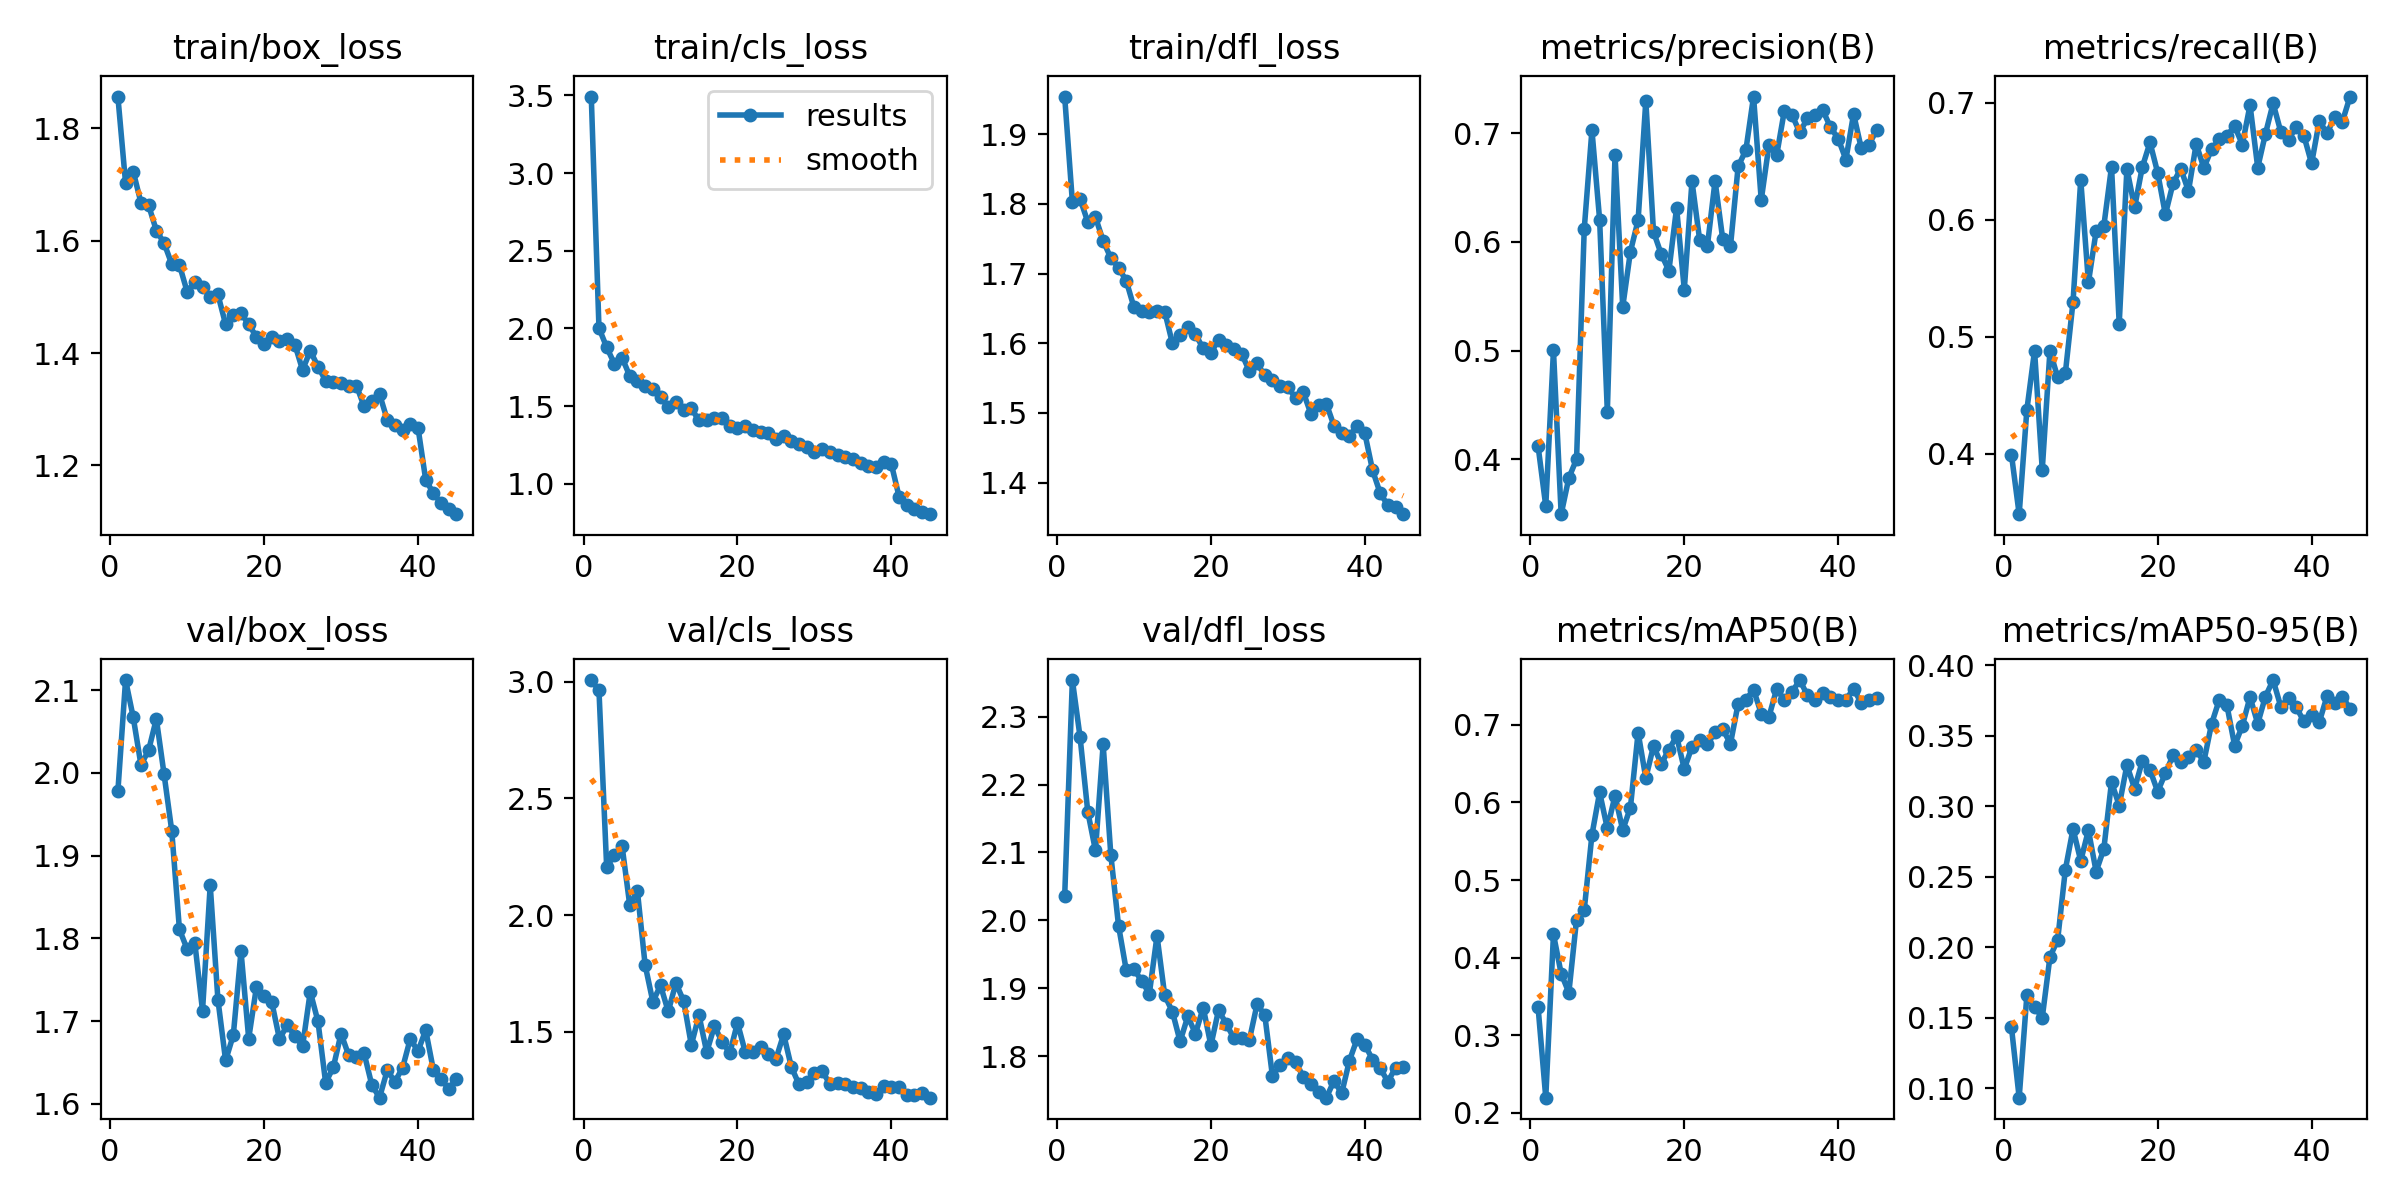


confusion_matrix.png


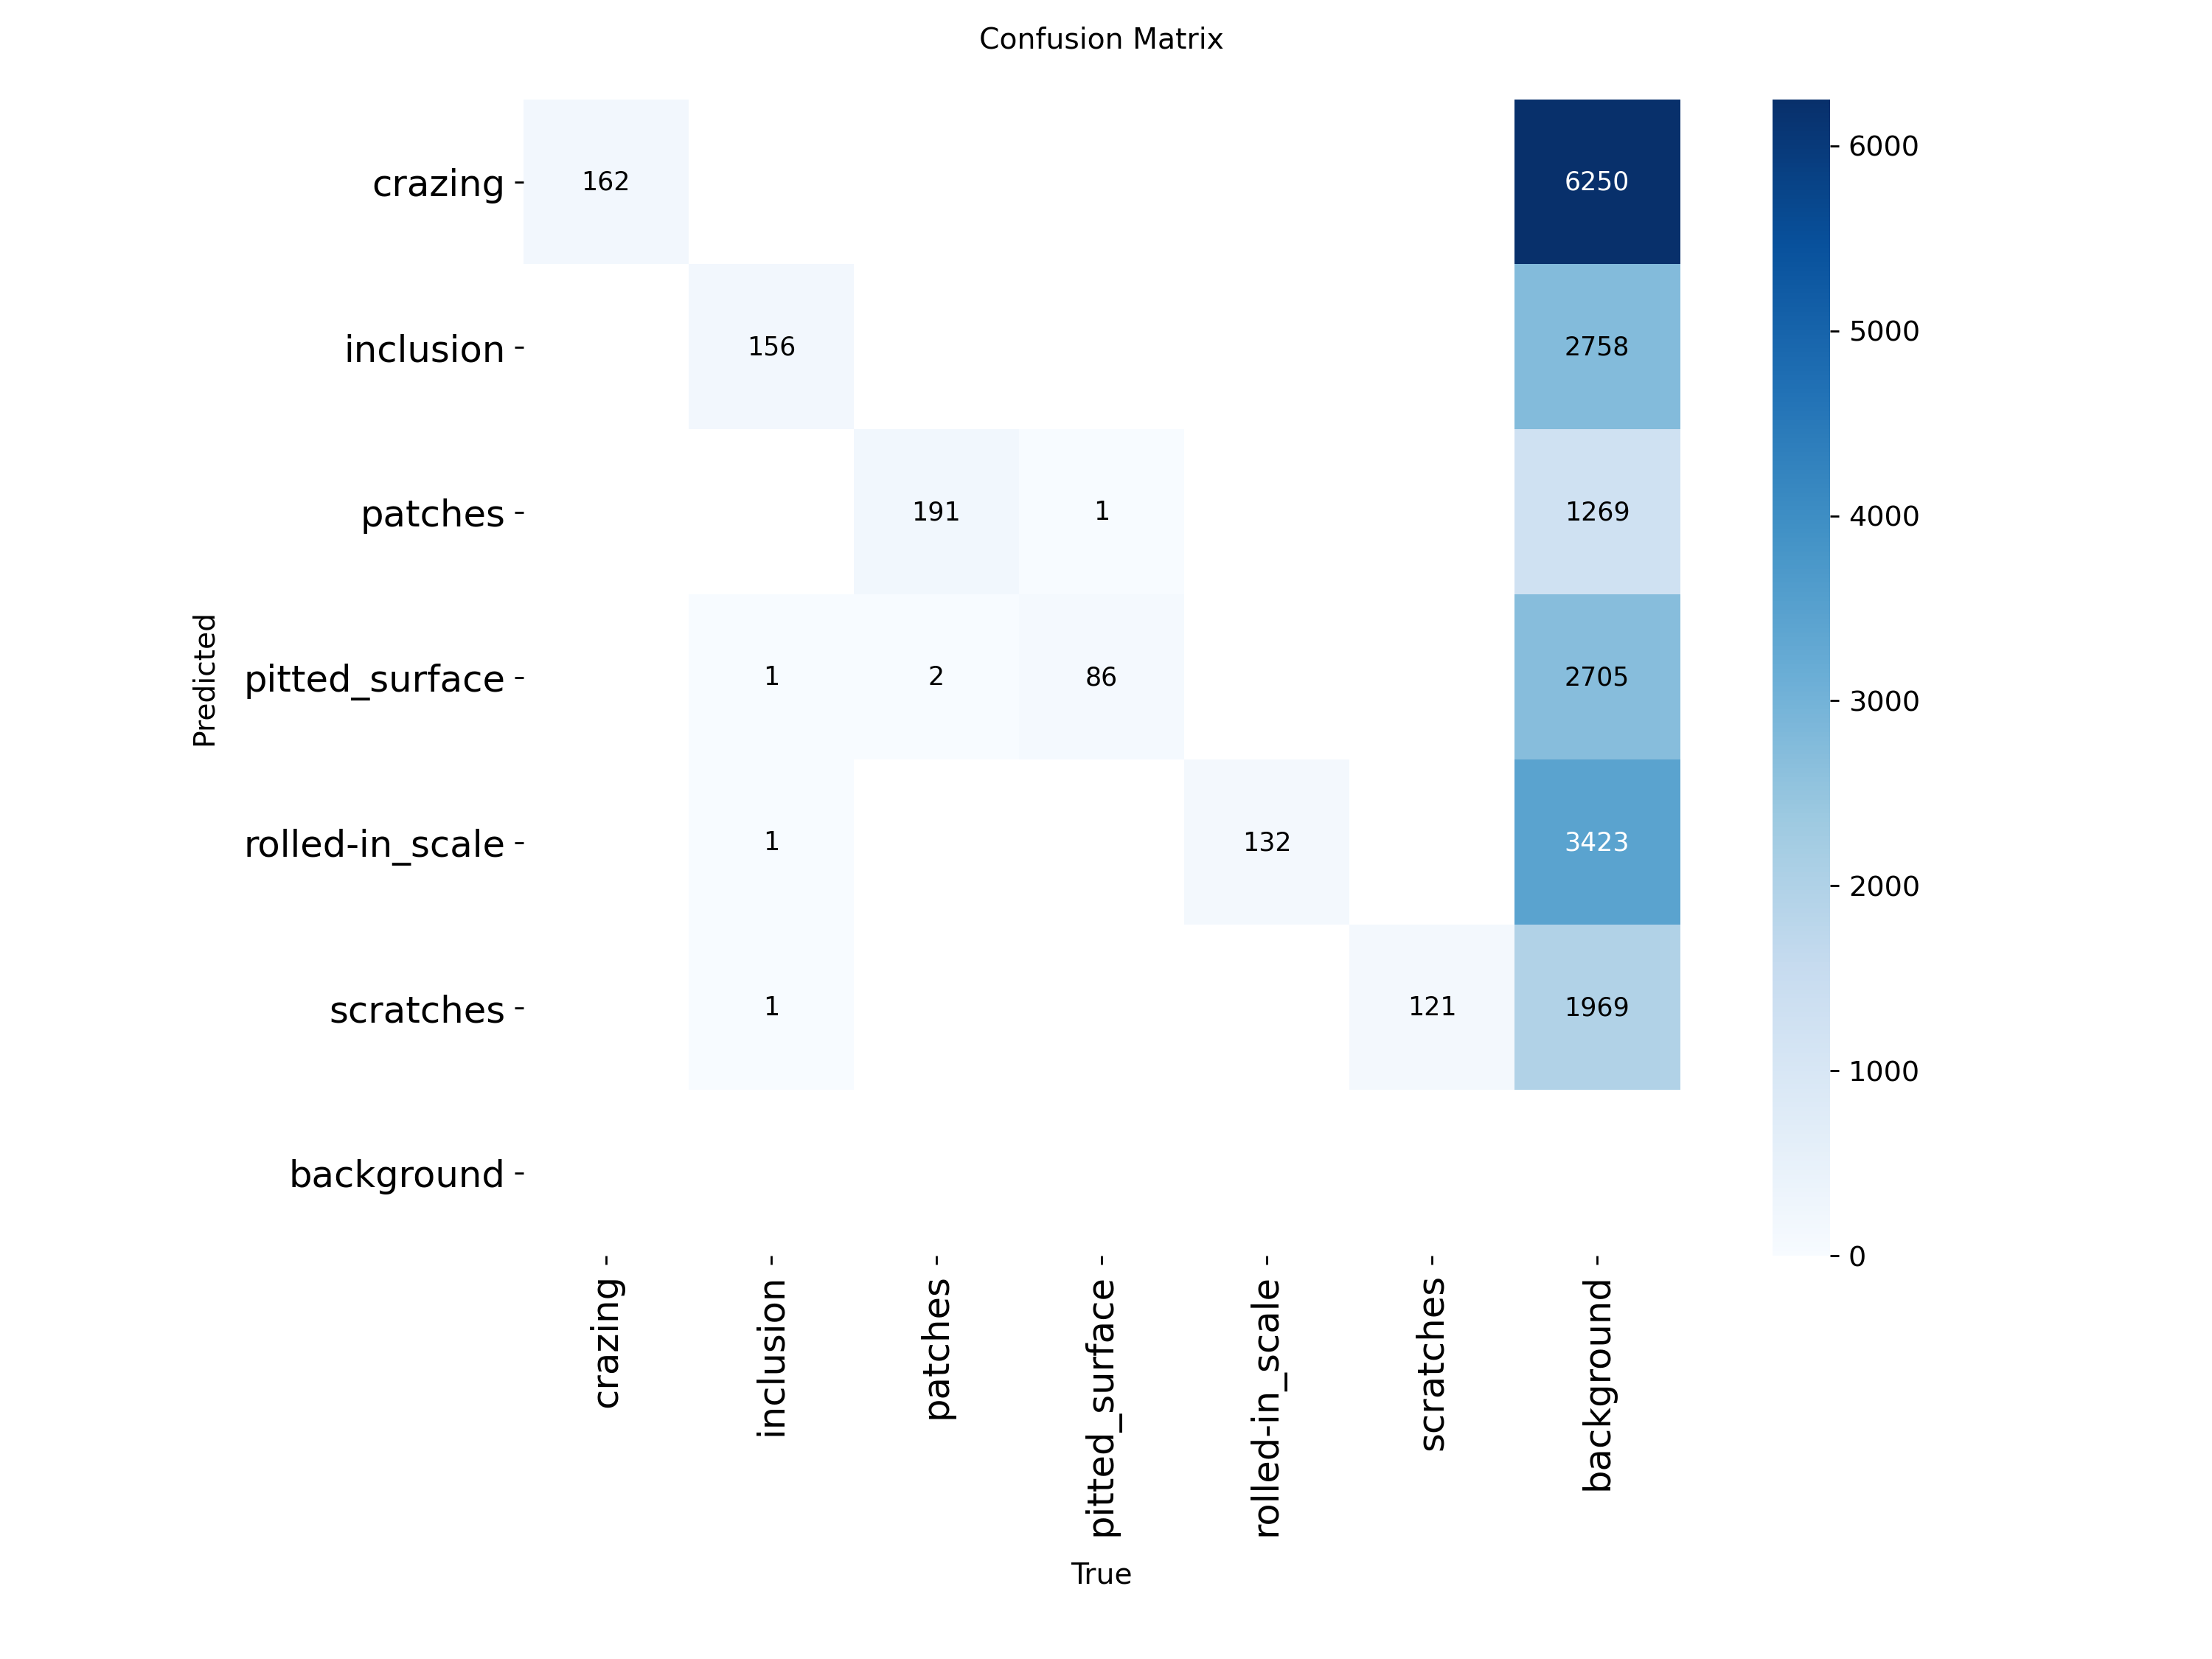

PR_curve.png not found yet.
F1_curve.png not found yet.


In [ ]:
from IPython.display import Image, display
from pathlib import Path

RUN_DIR = Path("/content/ps7_runs/neu_yolo11n_augmented")

for filename in ["results.png", "confusion_matrix.png",
                 "PR_curve.png", "F1_curve.png"]:
    image_path = RUN_DIR / filename

    if image_path.exists():
        print(f"\n{filename}")
        display(Image(filename=str(image_path)))
    else:
        print(f"{filename} not found yet.")


0: 640x640 4 patchess, 6.5ms
1: 640x640 2 crazings, 6.5ms
2: 640x640 2 pitted_surfaces, 6.5ms
3: 640x640 4 inclusions, 6.5ms
4: 640x640 4 rolled-in_scales, 6.5ms
5: 640x640 1 scratches, 6.5ms
Speed: 1.5ms preprocess, 6.5ms inference, 3.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/ps7_runs/neu_yolo11n_predictions
Predictions saved to: /content/ps7_runs/neu_yolo11n_predictions
Image: patches_99.jpg


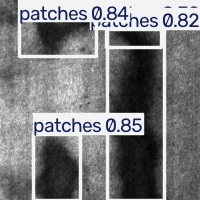

Image: crazing_194.jpg


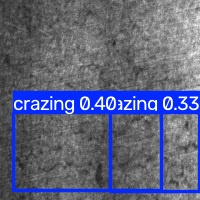

Image: pitted_surface_143.jpg


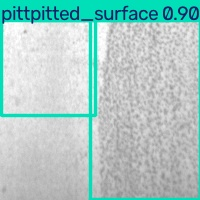

Image: inclusion_178.jpg


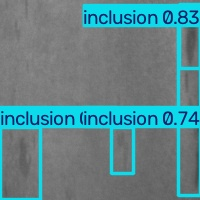

Image: rolled-in_scale_77.jpg


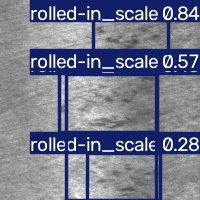

Image: scratches_52.jpg


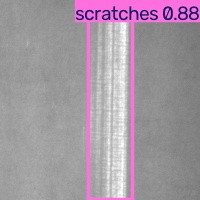

In [ ]:
from pathlib import Path
from IPython.display import Image, display
import random

TEST_IMAGES = Path("/content/neu_yolo/images/test")
PREDICTION_DIR = Path("/content/ps7_runs/neu_yolo11n_predictions")

image_files = list(TEST_IMAGES.glob("*.jpg"))

assert image_files, "No test images found."

sample_images = random.Random(42).sample(
    image_files,
    min(6, len(image_files))
)

prediction_results = model.predict(
    source=[str(p) for p in sample_images],
    imgsz=640,
    conf=0.25,
    iou=0.45,
    device=0,
    save=True,
    project="/content/ps7_runs",
    name="neu_yolo11n_predictions",
    exist_ok=True
)

print("Predictions saved to:", PREDICTION_DIR)

for result in prediction_results:
    print("Image:", Path(result.path).name)
    display(Image(filename=result.save_dir and str(
        PREDICTION_DIR / Path(result.path).name
    )))


0: 640x640 4 patchess, 6.5ms
1: 640x640 2 crazings, 6.5ms
2: 640x640 2 pitted_surfaces, 6.5ms
3: 640x640 4 inclusions, 6.5ms
4: 640x640 4 rolled-in_scales, 6.5ms
5: 640x640 1 scratches, 6.5ms
Speed: 1.6ms preprocess, 6.5ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/ps7_runs/neu_yolo11n_predictions
Predictions saved to: /content/ps7_runs/neu_yolo11n_predictions
Image: patches_99.jpg


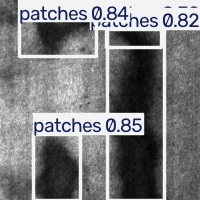

Image: crazing_194.jpg


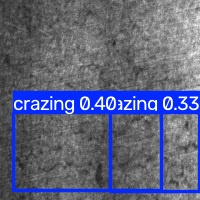

Image: pitted_surface_143.jpg


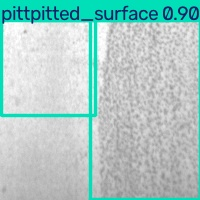

Image: inclusion_178.jpg


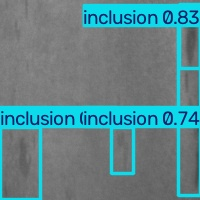

Image: rolled-in_scale_77.jpg


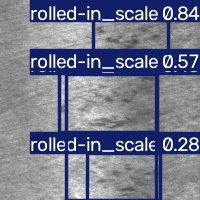

Image: scratches_52.jpg


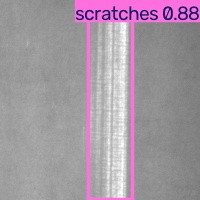

In [ ]:
from pathlib import Path
from IPython.display import Image, display
import random

TEST_IMAGES = Path("/content/neu_yolo/images/test")
PREDICTION_DIR = Path("/content/ps7_runs/neu_yolo11n_predictions")

image_files = list(TEST_IMAGES.glob("*.jpg"))

assert image_files, "No test images found."

sample_images = random.Random(42).sample(
    image_files,
    min(6, len(image_files))
)

prediction_results = model.predict(
    source=[str(p) for p in sample_images],
    imgsz=640,
    conf=0.25,
    iou=0.45,
    device=0,
    save=True,
    project="/content/ps7_runs",
    name="neu_yolo11n_predictions",
    exist_ok=True
)

print("Predictions saved to:", PREDICTION_DIR)

for result in prediction_results:
    print("Image:", Path(result.path).name)
    display(Image(filename=result.save_dir and str(
        PREDICTION_DIR / Path(result.path).name
    )))

In [ ]:
from google.colab import files

files.download("/content/ps7_runs/neu_yolo11n_augmented/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

metrics = pd.DataFrame([{
    "Model": "YOLO11n",
    "Dataset": "NEU-DET",
    "Precision": test_results.box.mp,
    "Recall": test_results.box.mr,
    "mAP50": test_results.box.map50,
    "mAP50_95": test_results.box.map
}])

metrics.to_csv(
    "/content/ps7_test_metrics.csv",
    index=False
)

display(metrics)

files.download("/content/ps7_test_metrics.csv")

,Model,Dataset,Precision,Recall,mAP50,mAP50_95
0,YOLO11n,NEU-DET,0.747913,0.680986,0.758338,0.413465


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from pathlib import Path
import xml.etree.ElementTree as ET
import random
import shutil
import yaml

# Source dataset
SOURCE = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")
OUTPUT = Path("/content/neu_yolo")

CLASSES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

# Start with clean output folders
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in ["train", "val", "test"]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

# Collect image/XML pairs from the original train folder
pairs = []
for img in (SOURCE / "train" / "images").glob("*"):
    if img.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
        xml = SOURCE / "train" / "annotations" / (img.stem + ".xml")
        if xml.exists():
            pairs.append((img, xml))

# Hold out a class-balanced sample from original training data
random.seed(42)
random.shuffle(pairs)
test_pairs = pairs[:180]
train_pairs = pairs[180:]

# Keep original validation data for validation
val_pairs = []
for img in (SOURCE / "validation" / "images").glob("*"):
    if img.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
        xml = SOURCE / "validation" / "annotations" / (img.stem + ".xml")
        if xml.exists():
            val_pairs.append((img, xml))

class_to_id = {name: i for i, name in enumerate(CLASSES)}

def convert_pair(img, xml, split):
    root = ET.parse(xml).getroot()
    width = float(root.findtext("size/width"))
    height = float(root.findtext("size/height"))
    lines = []

    for obj in root.findall("object"):
        name = obj.findtext("name")
        if name not in class_to_id:
            continue

        box = obj.find("bndbox")
        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        xc = ((xmin + xmax) / 2) / width
        yc = ((ymin + ymax) / 2) / height
        bw = (xmax - xmin) / width
        bh = (ymax - ymin) / height

        lines.append(
            f"{class_to_id[name]} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
        )

    if not lines:
        return False

    dest_img = OUTPUT / "images" / split / img.name
    dest_label = OUTPUT / "labels" / split / (img.stem + ".txt")

    shutil.copy2(img, dest_img)
    dest_label.write_text("\n".join(lines) + "\n")
    return True

counts = {}
for split, items in [
    ("train", train_pairs),
    ("val", val_pairs),
    ("test", test_pairs)
]:
    count = sum(convert_pair(img, xml, split) for img, xml in items)
    counts[split] = count

config = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(CLASSES)}
}

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Dataset preparation finished!")
print("Images copied:", counts)
print("Configuration:", OUTPUT / "data.yaml")
print("Class names:", CLASSES)

Dataset preparation finished!
Images copied: {'train': 0, 'val': 0, 'test': 0}
Configuration: /content/neu_yolo/data.yaml
Class names: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [11]:
from pathlib import Path

SOURCE = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")

for split in ["train", "validation"]:
    print(f"\n--- {split.upper()} ---")

    for subfolder in ["images", "annotations"]:
        folder = SOURCE / split / subfolder
        print(f"\n{subfolder} exists:", folder.exists())

        if folder.exists():
            files = list(folder.iterdir())
            print("Number of entries:", len(files))
            print("First 10 entries:")
            for f in files[:10]:
                print(" ", f.name)


--- TRAIN ---

images exists: True
Number of entries: 6
First 10 entries:
  inclusion
  scratches
  pitted_surface
  patches
  crazing
  rolled-in_scale

annotations exists: True
Number of entries: 1439
First 10 entries:
  patches_36.xml
  inclusion_147.xml
  crazing_200.xml
  rolled-in_scale_32.xml
  rolled-in_scale_61.xml
  pitted_surface_47.xml
  rolled-in_scale_142.xml
  crazing_160.xml
  patches_21.xml
  patches_207.xml

--- VALIDATION ---

images exists: True
Number of entries: 6
First 10 entries:
  inclusion
  scratches
  pitted_surface
  patches
  crazing
  rolled-in_scale

annotations exists: True
Number of entries: 361
First 10 entries:
  scratches_246.xml
  patches_258.xml
  crazing_241.xml
  patches_267.xml
  crazing_270.xml
  pitted_surface_256.xml
  pitted_surface_265.xml
  pitted_surface_287.xml
  crazing_265.xml
  rolled-in_scale_288.xml


In [12]:

from pathlib import Path

SOURCE = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")

for split in ["train", "validation"]:
    image_root = SOURCE / split / "images"
    annotation_root = SOURCE / split / "annotations"

    print(f"\n--- {split.upper()} ---")

    image_files = list(image_root.rglob("*"))
    image_files = [
        f for f in image_files
        if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    xml_files = list(annotation_root.glob("*.xml"))

    print("Total images:", len(image_files))
    print("Total XML annotations:", len(xml_files))

    print("\nExample images:")
    for f in image_files[:5]:
        print(f.relative_to(image_root))

    print("\nExample annotations:")
    for f in xml_files[:5]:
        print(f.name)

    image_stems = {f.stem for f in image_files}
    xml_stems = {f.stem for f in xml_files}

    print("\nMatching filenames:", len(image_stems & xml_stems))
    print("Images without matching XML:", len(image_stems - xml_stems))
    print("XML without matching image:", len(xml_stems - image_stems))



--- TRAIN ---
Total images: 1440
Total XML annotations: 1439

Example images:
inclusion/inclusion_1.jpg
inclusion/inclusion_6.jpg
inclusion/inclusion_28.jpg
inclusion/inclusion_219.jpg
inclusion/inclusion_11.jpg

Example annotations:
patches_36.xml
inclusion_147.xml
crazing_200.xml
rolled-in_scale_32.xml
rolled-in_scale_61.xml

Matching filenames: 1439
Images without matching XML: 1
XML without matching image: 0

--- VALIDATION ---
Total images: 360
Total XML annotations: 361

Example images:
inclusion/inclusion_253.jpg
inclusion/inclusion_287.jpg
inclusion/inclusion_247.jpg
inclusion/inclusion_280.jpg
inclusion/inclusion_246.jpg

Example annotations:
scratches_246.xml
patches_258.xml
crazing_241.xml
patches_267.xml
crazing_270.xml

Matching filenames: 360
Images without matching XML: 0
XML without matching image: 1


In [13]:

from pathlib import Path

SOURCE = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")

for split in ["train", "validation"]:
    image_root = SOURCE / split / "images"
    annotation_root = SOURCE / split / "annotations"

    image_stems = {
        f.stem for f in image_root.rglob("*")
        if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    }

    xml_stems = {
        f.stem for f in annotation_root.glob("*.xml")
    }

    print(f"\n--- {split.upper()} ---")
    print("Images without XML:", sorted(image_stems - xml_stems))
    print("XML without images:", sorted(xml_stems - image_stems))



--- TRAIN ---
Images without XML: ['crazing_240']
XML without images: []

--- VALIDATION ---
Images without XML: []
XML without images: ['crazing_240']


In [14]:

from pathlib import Path
import xml.etree.ElementTree as ET

SOURCE = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")
xml_file = SOURCE / "train" / "annotations" / "crazing_200.xml"

root = ET.parse(xml_file).getroot()

print("Image filename:", root.findtext("filename"))
print("Image width:", root.findtext("size/width"))
print("Image height:", root.findtext("size/height"))

print("\nObjects:")
for obj in root.findall("object"):
    print("Class:", obj.findtext("name"))
    box = obj.find("bndbox")
    if box is not None:
        print("Bounding box:", {
            key: box.findtext(key)
            for key in ["xmin", "ymin", "xmax", "ymax"]
        })


Image filename: crazing_200.jpg
Image width: 200
Image height: 200

Objects:
Class: crazing
Bounding box: {'xmin': '42', 'ymin': '7', 'xmax': '176', 'ymax': '84'}
Class: crazing
Bounding box: {'xmin': '7', 'ymin': '97', 'xmax': '161', 'ymax': '146'}
Class: crazing
Bounding box: {'xmin': '4', 'ymin': '154', 'xmax': '92', 'ymax': '196'}


In [15]:

from pathlib import Path
import shutil
import xml.etree.ElementTree as ET
import yaml

SOURCE = Path("/kaggle/input/neu-surface-defect-database/NEU-DET")
OUTPUT = Path("/content/neu_yolo")

CLASSES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

# Re-create the output folder so old empty folders do not interfere.
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in ["train", "val"]:
    source_split = "train" if split == "train" else "validation"

    image_root = SOURCE / source_split / "images"
    annotation_root = SOURCE / source_split / "annotations"

    images_out = OUTPUT / "images" / split
    labels_out = OUTPUT / "labels" / split

    images_out.mkdir(parents=True, exist_ok=True)
    labels_out.mkdir(parents=True, exist_ok=True)

    xml_by_stem = {
        xml.stem: xml
        for xml in annotation_root.glob("*.xml")
    }

    image_files = [
        p for p in image_root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    copied = 0
    skipped = 0
    box_count = 0

    for image_path in image_files:
        xml_path = xml_by_stem.get(image_path.stem)

        # Skip an image when its annotation is missing.
        if xml_path is None:
            skipped += 1
            continue

        root = ET.parse(xml_path).getroot()

        width = int(root.findtext("size/width"))
        height = int(root.findtext("size/height"))

        yolo_lines = []

        for obj in root.findall("object"):
            class_name = obj.findtext("name")

            if class_name not in CLASSES:
                raise ValueError(
                    f"Unknown class '{class_name}' in {xml_path}"
                )

            box = obj.find("bndbox")
            xmin = float(box.findtext("xmin"))
            ymin = float(box.findtext("ymin"))
            xmax = float(box.findtext("xmax"))
            ymax = float(box.findtext("ymax"))

            # Convert corner coordinates to normalized YOLO format.
            x_center = ((xmin + xmax) / 2) / width
            y_center = ((ymin + ymax) / 2) / height
            box_width = (xmax - xmin) / width
            box_height = (ymax - ymin) / height

            class_id = CLASSES.index(class_name)

            yolo_lines.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{box_width:.6f} {box_height:.6f}"
            )
            box_count += 1

        # Do not copy images that have no valid objects.
        if not yolo_lines:
            skipped += 1
            continue

        shutil.copy2(
            image_path,
            images_out / image_path.name
        )

        label_path = labels_out / f"{image_path.stem}.txt"
        label_path.write_text("\n".join(yolo_lines) + "\n")

        copied += 1

    print(
        f"{split.upper()}: {copied} images prepared, "
        f"{skipped} images skipped, {box_count} boxes converted"
    )

# Write the YOLO dataset configuration.
data_config = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/val",
    "names": {i: name for i, name in enumerate(CLASSES)}
}

config_path = OUTPUT / "data.yaml"
with open(config_path, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("\nConfiguration saved to:", config_path)
print("Training images:", len(list((OUTPUT / "images/train").glob("*"))))
print("Validation images:", len(list((OUTPUT / "images/val").glob("*"))))
print("Training labels:", len(list((OUTPUT / "labels/train").glob("*.txt"))))
print("Validation labels:", len(list((OUTPUT / "labels/val").glob("*.txt"))))


TRAIN: 1439 images prepared, 1 images skipped, 3332 boxes converted
VAL: 360 images prepared, 0 images skipped, 854 boxes converted

Configuration saved to: /content/neu_yolo/data.yaml
Training images: 1439
Validation images: 360
Training labels: 1439
Validation labels: 360


In [16]:

from ultralytics import YOLO
from pathlib import Path
import yaml

model_path = Path("/content/best.pt")
data_path = Path("/content/neu_yolo/data.yaml")

print("Checkpoint exists:", model_path.exists())
print("Dataset config exists:", data_path.exists())

model = YOLO(str(model_path))

print("\nCheckpoint classes:")
print(model.names)

print("\nDataset classes:")
with open(data_path) as f:
    data = yaml.safe_load(f)

print(data["names"])

print("\nRunning dataset validation...")
model.val(
    data=str(data_path),
    imgsz=640,
    batch=16,
    split="val",
    plots=False
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Checkpoint exists: True
Dataset config exists: True

Checkpoint classes:
{0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted_surface', 4: 'rolled-in_scale', 5: 'scratches'}

Dataset classes:
{0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted_surface', 4: 'rolled-in_scale', 5: 'scratches'}

Running dataset validation...
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 667.8±401.5 MB/s, size: 17.7 KB)
val: Scanning /content/neu_yolo/labels/val... 360 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 360/360 1.8Kit/s 0.2s
val

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d80ac2bd550>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

In [17]:

from ultralytics import YOLO
from pathlib import Path

# Confirm the required files exist
assert Path("/content/best.pt").exists(), "best.pt is missing"
assert Path("/content/neu_yolo/data.yaml").exists(), "data.yaml is missing"

# Load the existing trained model, not a new model
model = YOLO("/content/best.pt")

# Fine-tune and save to a separate location
results = model.train(
    data="/content/neu_yolo/data.yaml",
    epochs=25,
    imgsz=640,
    batch=16,
    lr0=0.001,
    patience=8,
    project="/content/neu_finetune",
    name="yolo11n_finetuned",
    exist_ok=True,
    seed=42,
    plots=True,
    save=True
)

print("\nTraining finished.")
print("Results folder: /content/neu_finetune/yolo11n_finetuned")
print("Best checkpoint: /content/neu_finetune/yolo11n_finetuned/weights/best.pt")


Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_finetuned, nbs=64, nms=None, opset=None, optimiz

In [1]:
from google.colab import files

files.download(
    "/content/neu_finetune/yolo11n_finetuned/weights/best.pt"
)

FileNotFoundError: Cannot find file: /content/neu_finetune/yolo11n_finetuned/weights/best.pt

In [2]:
import os

for folder in ["/content", "/content/neu_finetune", "/content/runs"]:
    print(f"\nChecking: {folder}")
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.endswith(".pt"):
                    print(os.path.join(root, file))
    else:
        print("Folder not found")


Checking: /content

Checking: /content/neu_finetune
Folder not found

Checking: /content/runs
Folder not found


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os

found = False

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))
            found = True

if not found:
    print("No .pt model files found in Google Drive.")

MessageError: Error: credential propagation was unsuccessful

In [4]:
import os

print(os.path.exists("/content/best.pt"))

True


In [5]:
from ultralytics import YOLO

model = YOLO("/content/best.pt")
print("Model loaded successfully!")
print("Task:", model.task)
print("Classes:", model.names)

ModuleNotFoundError: No module named 'ultralytics'

In [6]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [7]:
from ultralytics import YOLO

model = YOLO("/content/best.pt")

print("Model loaded successfully!")
print("Task:", model.task)
print("Classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded successfully!
Task: detect
Classes: {0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted_surface', 4: 'rolled-in_scale', 5: 'scratches'}


In [9]:
import os

for path in [
    "/content/neu_yolo/data.yaml",
    "/content/neu_yolo/images/train",
    "/content/neu_yolo/images/val",
]:
    print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")

/content/neu_yolo/data.yaml NOT FOUND
/content/neu_yolo/images/train NOT FOUND
/content/neu_yolo/images/val NOT FOUND


In [10]:
!pip install -q kagglehub

In [11]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Dataset downloaded to:", dataset_path)
print("Contents:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset downloaded to: /kaggle/input/neu-surface-defect-database
Contents: ['NEU-DET']


In [12]:
import os

root = "/kaggle/input/neu-surface-defect-database/NEU-DET"

for current, dirs, files in os.walk(root):
    level = current.replace(root, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(current) + "/")
        if level == 2:
            print("  " * (level + 1) + f"{len(files)} files")

NEU-DET/
  validation/
    annotations/
      361 files
    images/
      0 files
  train/
    annotations/
      1439 files
    images/
      0 files


In [13]:
import os

root = "/kaggle/input/neu-surface-defect-database/NEU-DET"

for split in ["train", "validation"]:
    image_root = os.path.join(root, split, "images")
    print(f"\n{split.upper()}")

    for current, dirs, files in os.walk(image_root):
        images = [
            f for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]
        if images:
            print(current, "->", len(images), "images")
            print("Examples:", images[:3])


TRAIN
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/inclusion -> 240 images
Examples: ['inclusion_1.jpg', 'inclusion_6.jpg', 'inclusion_28.jpg']
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/scratches -> 240 images
Examples: ['scratches_141.jpg', 'scratches_95.jpg', 'scratches_129.jpg']
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/pitted_surface -> 240 images
Examples: ['pitted_surface_37.jpg', 'pitted_surface_117.jpg', 'pitted_surface_21.jpg']
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/patches -> 240 images
Examples: ['patches_89.jpg', 'patches_131.jpg', 'patches_41.jpg']
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/crazing -> 240 images
Examples: ['crazing_1.jpg', 'crazing_45.jpg', 'crazing_199.jpg']
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/rolled-in_scale -> 240 images
Examples: ['rolled-in_scale_178.jpg', 'rolled-in_scale_223.jpg', 'rolled-in_scale_129.jpg']

VALIDATION


In [14]:
import os
import shutil
import xml.etree.ElementTree as ET
import yaml

source = "/kaggle/input/neu-surface-defect-database/NEU-DET"
output = "/content/neu_yolo"

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

# Create output folders
if os.path.exists(output):
    shutil.rmtree(output)

for split in ["train", "val"]:
    os.makedirs(f"{output}/images/{split}", exist_ok=True)
    os.makedirs(f"{output}/labels/{split}", exist_ok=True)

# Convert XML annotations to YOLO format
for split in ["train", "val"]:
    source_split = "train" if split == "train" else "validation"
    image_root = f"{source}/{source_split}/images"
    annotation_root = f"{source}/{source_split}/annotations"

    count = 0
    skipped = 0

    for class_name in classes:
        class_folder = f"{image_root}/{class_name}"

        for filename in os.listdir(class_folder):
            if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            image_path = os.path.join(class_folder, filename)
            xml_path = os.path.join(
                annotation_root, os.path.splitext(filename)[0] + ".xml"
            )

            if not os.path.exists(xml_path):
                skipped += 1
                continue

            root = ET.parse(xml_path).getroot()
            size = root.find("size")

            if size is None:
                skipped += 1
                continue

            width = float(size.findtext("width"))
            height = float(size.findtext("height"))

            if width <= 0 or height <= 0:
                skipped += 1
                continue

            labels = []

            for obj in root.findall("object"):
                name = obj.findtext("name")
                if name not in classes:
                    continue

                box = obj.find("bndbox")
                if box is None:
                    continue

                xmin = float(box.findtext("xmin"))
                ymin = float(box.findtext("ymin"))
                xmax = float(box.findtext("xmax"))
                ymax = float(box.findtext("ymax"))

                # Clip coordinates to image boundaries
                xmin = max(0, min(xmin, width))
                xmax = max(0, min(xmax, width))
                ymin = max(0, min(ymin, height))
                ymax = max(0, min(ymax, height))

                if xmax <= xmin or ymax <= ymin:
                    continue

                x_center = ((xmin + xmax) / 2) / width
                y_center = ((ymin + ymax) / 2) / height
                box_width = (xmax - xmin) / width
                box_height = (ymax - ymin) / height

                class_id = classes.index(name)
                labels.append(
                    f"{class_id} {x_center:.6f} {y_center:.6f} "
                    f"{box_width:.6f} {box_height:.6f}"
                )

            if not labels:
                skipped += 1
                continue

            shutil.copy2(
                image_path,
                f"{output}/images/{split}/{filename}"
            )

            label_name = os.path.splitext(filename)[0] + ".txt"
            with open(f"{output}/labels/{split}/{label_name}", "w") as f:
                f.write("\n".join(labels))

            count += 1

    print(f"{split}: {count} images converted; {skipped} skipped")

# Write YOLO dataset configuration
data = {
    "path": output,
    "train": "images/train",
    "val": "images/val",
    "names": {i: name for i, name in enumerate(classes)}
}

with open(f"{output}/data.yaml", "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("\nDataset configuration saved:", f"{output}/data.yaml")

train: 1439 images converted; 1 skipped
val: 360 images converted; 0 skipped

Dataset configuration saved: /content/neu_yolo/data.yaml


In [15]:
import os
import torch
from ultralytics import YOLO

print("Original checkpoint exists:", os.path.exists("/content/best.pt"))
print("Dataset config exists:", os.path.exists("/content/neu_yolo/data.yaml"))
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Original checkpoint exists: True
Dataset config exists: True
GPU available: True
GPU: Tesla T4


In [16]:
from ultralytics import YOLO

# Load the original model
model = YOLO("/content/best.pt")

# Fine-tune on the NEU steel surface defect dataset
results = model.train(
    data="/content/neu_yolo/data.yaml",
    epochs=25,
    imgsz=640,
    batch=16,
    patience=8,
    project="/content/neu_finetune",
    name="yolo11n_finetuned",
    exist_ok=True,
    seed=42,
    plots=True,
    save=True
)

print("Fine-tuning completed!")
print("Model saved at:")
print("/content/neu_finetune/yolo11n_finetuned/weights/best.pt")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_finetuned, nbs=64, nms=None, opset=None, optimize

In [17]:
import os
from google.colab import files

model_path = "/content/neu_finetune/yolo11n_finetuned/weights/best.pt"

print("Model exists:", os.path.exists(model_path))
print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

files.download(model_path)

Model exists: True
Model size: 5.25 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
import os
import shutil

source = "/content/neu_finetune/yolo11n_finetuned/weights/best.pt"
destination = f"{PROJECT_DIR}/models/best.pt"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("Fine-tuned model backed up successfully!")
    print("File size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
else:
    print("Source model not found. Check the model path before continuing.")

NameError: name 'PROJECT_DIR' is not defined

In [20]:
import os
import shutil

# Define the permanent Google Drive folder
PROJECT_DIR = "/content/drive/MyDrive/IBM_Quality_Inspection"

# Create the models folder
os.makedirs(f"{PROJECT_DIR}/models", exist_ok=True)

# Fine-tuned model location in Colab
source = "/content/neu_finetune/yolo11n_finetuned/weights/best.pt"

# Permanent model location in Google Drive
destination = f"{PROJECT_DIR}/models/best.pt"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("SUCCESS! Fine-tuned model saved in Google Drive.")
    print("Location:", destination)
    print("Size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
else:
    print("Model not found in the current Colab runtime.")
    print("Check whether the training output still exists.")

SUCCESS! Fine-tuned model saved in Google Drive.
Location: /content/drive/MyDrive/IBM_Quality_Inspection/models/best.pt
Size: 5.25 MB


In [21]:
import os
import shutil

PROJECT_DIR = "/content/drive/MyDrive/IBM_Quality_Inspection"

# Sources in the current Colab runtime
items = {
    "/content/neu_yolo": f"{PROJECT_DIR}/dataset/neu_yolo",
    "/content/neu_finetune/yolo11n_finetuned": f"{PROJECT_DIR}/training_results/yolo11n_finetuned"
}

for source, destination in items.items():
    if os.path.exists(source):
        if os.path.exists(destination):
            shutil.copytree(source, destination, dirs_exist_ok=True)
        else:
            shutil.copytree(source, destination)
        print("BACKED UP:", destination)
    else:
        print("NOT FOUND:", source)

print("\nBackup check:")
for folder in ["models", "dataset", "training_results"]:
    path = os.path.join(PROJECT_DIR, folder)
    print(folder, "->", os.path.exists(path))

BACKED UP: /content/drive/MyDrive/IBM_Quality_Inspection/dataset/neu_yolo
BACKED UP: /content/drive/MyDrive/IBM_Quality_Inspection/training_results/yolo11n_finetuned

Backup check:
models -> True
dataset -> True
training_results -> True


In [22]:
import os

base = "/content/drive/MyDrive/IBM_Quality_Inspection"

paths = {
    "Fine-tuned model": f"{base}/models/best.pt",
    "Converted dataset": f"{base}/dataset/neu_yolo/data.yaml",
    "Training results": f"{base}/training_results/yolo11n_finetuned",
}

for name, path in paths.items():
    print(f"{name}: {'SAVED' if os.path.exists(path) else 'MISSING'}")

Fine-tuned model: SAVED
Converted dataset: SAVED
Training results: SAVED
